# Assignment 2: Plotting a Binomial Distribution Curve in Python

**Learning outcomes**
- Understand the concept and mathematical basis of the binomial distribution.
- Use scipy.stats, numpy and matplotlib to model it.
- See how the parameters *n* (number of trials) and *p* (success probability) change its shape.
- Relate the distribution to real decisions.

The binomial distribution describes the number of successes in *n* independent trials, each with success probability *p*. Its mean is **np** and its variance is **np(1 − p)**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

np.random.seed(7)
plt.rcParams["figure.figsize"] = (9, 5)


## 1. Probability mass function (PMF)

The PMF gives P(X = k) for each possible number of successes k.

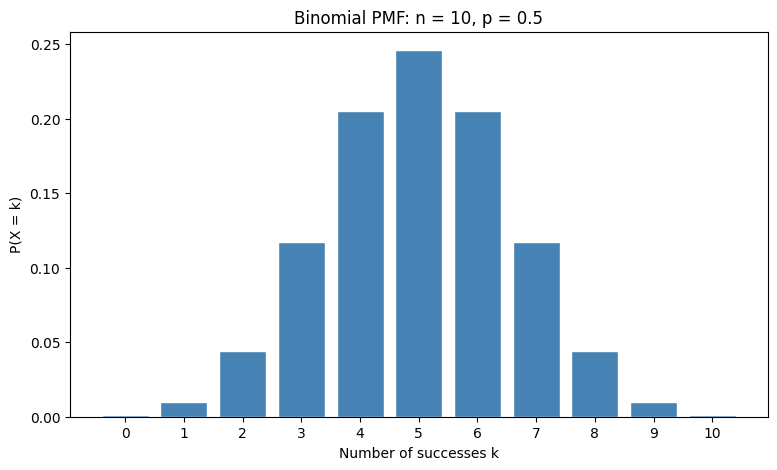

Mean (np): 5.0 | scipy mean: 5.0
Variance np(1-p): 2.5 | scipy var: 2.5


In [2]:
n, p = 10, 0.5
k = np.arange(0, n + 1)
pmf = stats.binom.pmf(k, n, p)

fig, ax = plt.subplots()
ax.bar(k, pmf, color="steelblue", edgecolor="white")
ax.set_title(f"Binomial PMF: n = {n}, p = {p}")
ax.set_xlabel("Number of successes k")
ax.set_ylabel("P(X = k)")
ax.set_xticks(k)
plt.show()

print("Mean (np):", n * p, "| scipy mean:", stats.binom.mean(n, p))
print("Variance np(1-p):", round(n * p * (1 - p), 3), "| scipy var:", round(stats.binom.var(n, p), 3))


## 2. How the parameters change the shape

- For a fixed *p*, a larger *n* spreads the distribution out and moves its centre to the right.
- When *p* is close to 0.5 the shape is roughly symmetric. When *p* is small or large it is skewed.

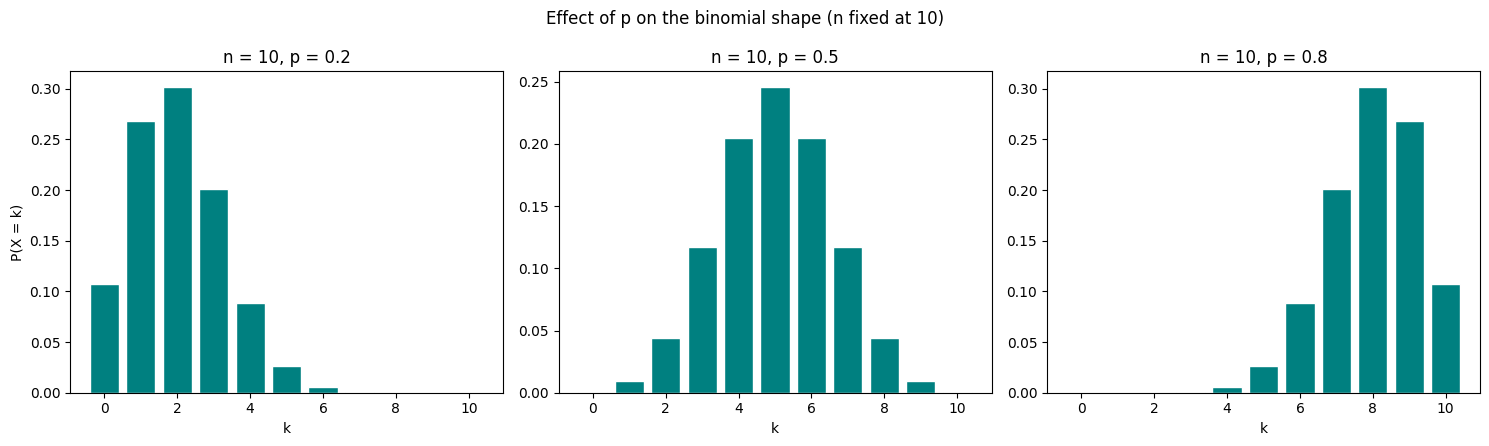

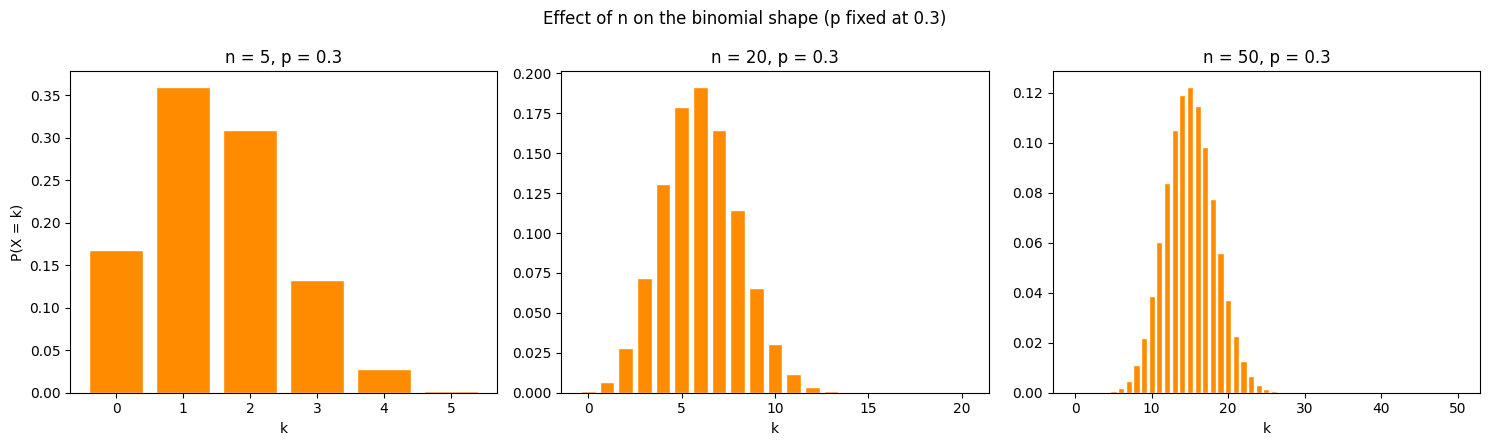

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=False)
combos = [(10, 0.2), (10, 0.5), (10, 0.8)]
for ax, (nn, pp) in zip(axes, combos):
    kk = np.arange(nn + 1)
    ax.bar(kk, stats.binom.pmf(kk, nn, pp), color="teal", edgecolor="white")
    ax.set_title(f"n = {nn}, p = {pp}")
    ax.set_xlabel("k")
axes[0].set_ylabel("P(X = k)")
fig.suptitle("Effect of p on the binomial shape (n fixed at 10)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, nn in zip(axes, [5, 20, 50]):
    kk = np.arange(nn + 1)
    ax.bar(kk, stats.binom.pmf(kk, nn, 0.3), color="darkorange", edgecolor="white")
    ax.set_title(f"n = {nn}, p = 0.3")
    ax.set_xlabel("k")
axes[0].set_ylabel("P(X = k)")
fig.suptitle("Effect of n on the binomial shape (p fixed at 0.3)")
plt.tight_layout()
plt.show()


## 3. Check the theory with simulation

We run many experiments and compare the observed frequencies with the theoretical PMF. With enough repetitions they should match closely.

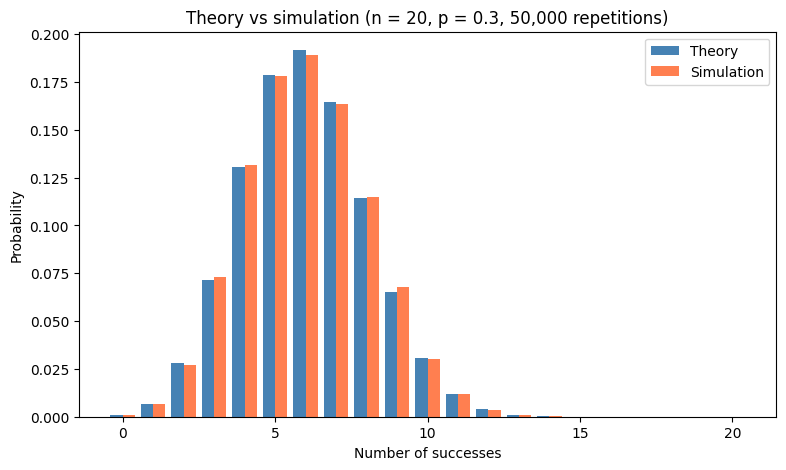

Largest gap between theory and simulation: 0.0026


In [4]:
n, p, reps = 20, 0.3, 50_000
simulated = np.random.binomial(n, p, reps)

k = np.arange(n + 1)
observed = np.bincount(simulated, minlength=n + 1) / reps

fig, ax = plt.subplots()
ax.bar(k - 0.2, stats.binom.pmf(k, n, p), width=0.4, label="Theory", color="steelblue")
ax.bar(k + 0.2, observed, width=0.4, label="Simulation", color="coral")
ax.set_title(f"Theory vs simulation (n = {n}, p = {p}, {reps:,} repetitions)")
ax.set_xlabel("Number of successes")
ax.set_ylabel("Probability")
ax.legend()
plt.show()

print("Largest gap between theory and simulation:",
      round(np.max(np.abs(observed - stats.binom.pmf(k, n, p))), 4))


## 4. Case study: email marketing campaign (success rate)

A campaign sends 1,000 emails. Assume each email converts with probability **p = 0.03**. How many conversions should we expect, and how likely is it that we reach at least 40?

Expected conversions: 30
P(at least 40 conversions) = 0.044


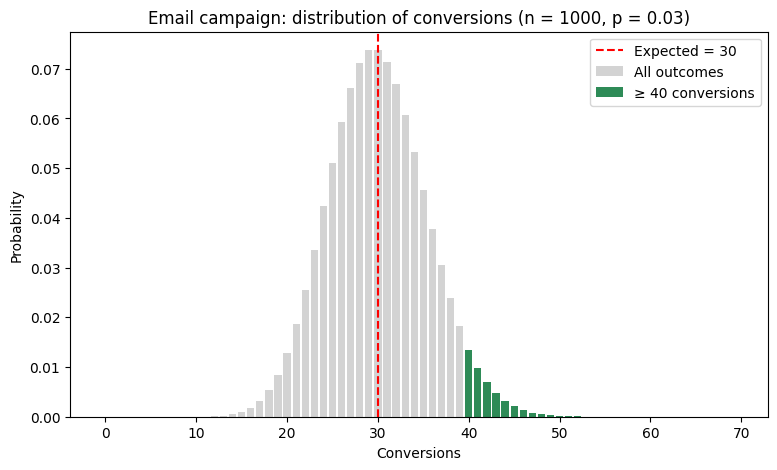

In [5]:
n, p = 1000, 0.03
expected = n * p
prob_at_least_40 = 1 - stats.binom.cdf(39, n, p)   # P(X >= 40)

print(f"Expected conversions: {expected:.0f}")
print(f"P(at least 40 conversions) = {prob_at_least_40:.3f}")

k = np.arange(0, 70)
fig, ax = plt.subplots()
ax.bar(k, stats.binom.pmf(k, n, p), color="lightgrey", label="All outcomes")
ax.bar(k[k >= 40], stats.binom.pmf(k[k >= 40], n, p), color="seagreen", label="≥ 40 conversions")
ax.axvline(expected, color="red", ls="--", label=f"Expected = {expected:.0f}")
ax.set_title("Email campaign: distribution of conversions (n = 1000, p = 0.03)")
ax.set_xlabel("Conversions")
ax.set_ylabel("Probability")
ax.legend()
plt.show()


## 5. Case study: clinical trial (drug success rate)

A drug is effective for 60% of patients (p = 0.6). A trial enrols 20 patients. What is the chance that at least 15 respond?

P(at least 15 of 20 respond) = 0.1256


Simulated estimate: 0.1237


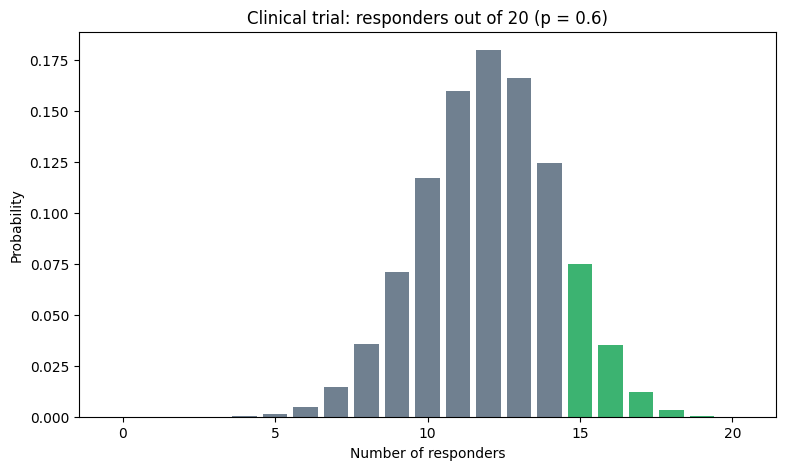

In [6]:
n, p = 20, 0.6
p_at_least_15 = 1 - stats.binom.cdf(14, n, p)
print(f"P(at least 15 of 20 respond) = {p_at_least_15:.4f}")

sim = np.random.binomial(n, p, 100_000)
print(f"Simulated estimate: {(sim >= 15).mean():.4f}")

k = np.arange(n + 1)
fig, ax = plt.subplots()
ax.bar(k, stats.binom.pmf(k, n, p), color="slategrey")
ax.bar(k[k >= 15], stats.binom.pmf(k[k >= 15], n, p), color="mediumseagreen")
ax.set_title("Clinical trial: responders out of 20 (p = 0.6)")
ax.set_xlabel("Number of responders")
ax.set_ylabel("Probability")
plt.show()


## 6. Case study: election polling

In a sample of 500 voters, suppose candidate A has true support of 52%. What is the probability that A wins a majority of the sample (more than 250 votes)? Sampling error means a poll can be wrong even when the underlying support is above 50%.

In [7]:
n, p = 500, 0.52
p_majority = 1 - stats.binom.cdf(250, n, p)     # P(X > 250)
print(f"P(majority in sample of 500) = {p_majority:.3f}")

for true_p in [0.48, 0.50, 0.52, 0.55]:
    prob = 1 - stats.binom.cdf(250, n, true_p)
    print(f"True support {true_p:.0%} -> P(sample majority) = {prob:.3f}")


P(majority in sample of 500) = 0.802
True support 48% -> P(sample majority) = 0.174
True support 50% -> P(sample majority) = 0.482
True support 52% -> P(sample majority) = 0.802
True support 55% -> P(sample majority) = 0.986


## 7. Interpretation

- The binomial model assumes independent trials with the same probability each time. Real campaigns and polls may break this (for example, email clicks can cluster), so check the assumption.
- A small *p* with a large *n* is often approximated by a Poisson distribution, which is useful for rare events.
- Decisions should use the tail probabilities (such as P(X ≥ 40)), not only the expected value.